# Women vs Men: ANSUR II body measurements

Classify soldiers as women or men from body measurements, and compare a single Decision Tree with a **bagged** ensemble of Decision Trees (`BaggingClassifier`, not `RandomForestClassifier`).

## A · Load ANSUR II

ANSUR II (US Army Anthropometric Survey, 2012) is distributed as two CSV files, `ANSUR II MALE Public.csv` and `ANSUR II FEMALE Public.csv` (OpenLab / Kaggle copies). The original files are only read, never modified.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

male = pd.read_csv('ANSUR II MALE Public.csv', encoding='latin1')
female = pd.read_csv('ANSUR II FEMALE Public.csv', encoding='latin1')
print('male:', male.shape, '| female:', female.shape)
print('Columns only in one file:', set(male.columns) ^ set(female.columns))

male: (4082, 108) | female: (1986, 108)
Columns only in one file: {'SubjectId', 'subjectid'}


## B · Preprocess and clean

1. The ID column is called `subjectid` in the male file and `SubjectId` in the female file, so unify it.
2. Add the target `Gender` and stack both files.
3. Remove duplicate rows and check missing values.
4. Keep numeric body measurements only: drop text/survey-metadata columns (e.g. `Ethnicity`, which is 66 % empty, `Branch`, `Component`, `WritingPreference`) and identifiers/metadata (`subjectid`, `SubjectNumericRace`, `DODRace`, `Age`).

In [2]:
female = female.rename(columns={'SubjectId': 'subjectid'})
male['Gender'] = 'Male'
female['Gender'] = 'Female'
data = pd.concat([male, female], ignore_index=True)
print('combined:', data.shape)

print('duplicate rows:', data.duplicated().sum())
data = data.drop_duplicates().reset_index(drop=True)

missing = data.isna().sum()
print('\ncolumns with missing values:'); print(missing[missing > 0])
print('\nnon-numeric columns:', list(data.select_dtypes(exclude='number').columns))

combined: (6068, 108)
duplicate rows: 0

columns with missing values:
Ethnicity    4647
dtype: int64

non-numeric columns: ['Gender', 'Date', 'Installation', 'Component', 'Branch', 'PrimaryMOS', 'SubjectsBirthLocation', 'Ethnicity', 'WritingPreference']


In [3]:
drop_cols = ['subjectid', 'SubjectNumericRace', 'DODRace', 'Age']
text_cols = [c for c in data.select_dtypes(exclude='number').columns if c != 'Gender']
clean = data.drop(columns=drop_cols + text_cols)

# sanity checks: no NaNs, no impossible (<= 0) measurements
feature_cols = [c for c in clean.columns if c != 'Gender']
print('NaNs left:', int(clean.isna().sum().sum()))
bad = (clean[feature_cols] <= 0).any(axis=1)
print('rows with a non-positive measurement:', int(bad.sum()), '->', list(clean[feature_cols].columns[(clean[feature_cols] <= 0).any()]))
clean = clean[~bad].reset_index(drop=True)          # a weight of 0 lbs is impossible (missing value coded as 0)
print('final shape:', clean.shape, '->', len(feature_cols), 'numeric features')
print(clean['Gender'].value_counts())

NaNs left: 0
rows with a non-positive measurement: 1 -> ['Weightlbs']
final shape: (6067, 96) -> 95 numeric features
Gender
Male      4081
Female    1986
Name: count, dtype: int64


## C · Heights of women and men on the same figure

`stature` is body height in millimetres (the dataset also has `Heightin` in inches).

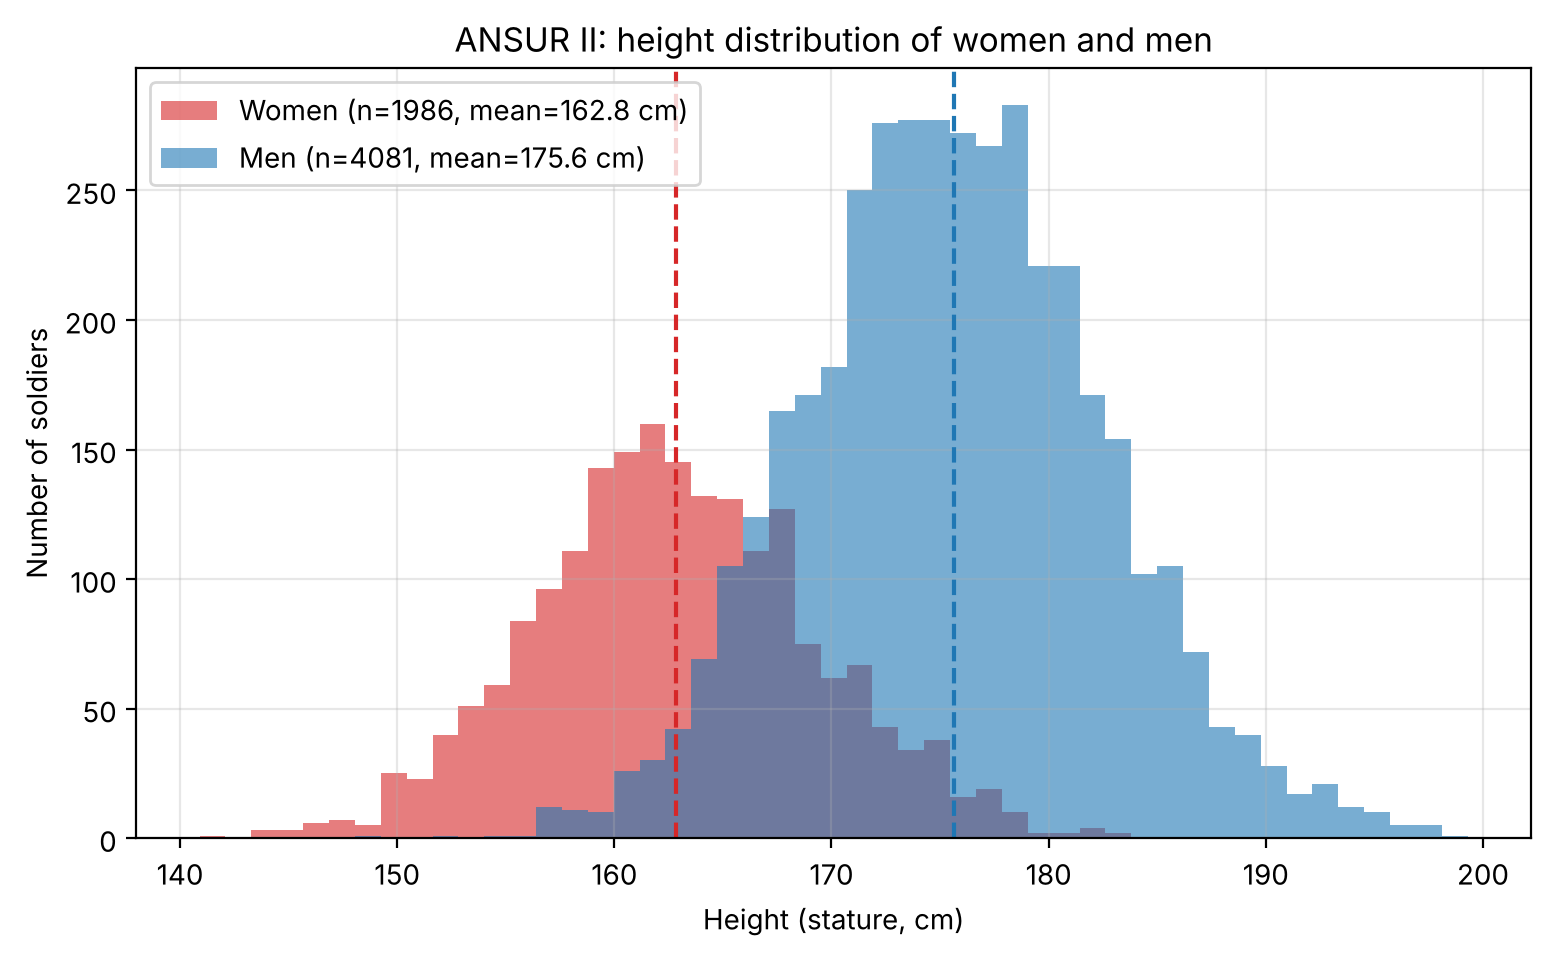

        Women     Men
count  1986.0  4081.0
mean    162.8   175.6
std       6.4     6.9
min     140.9   149.1
25%     158.6   171.0
50%     162.6   175.5
75%     167.2   180.2
max     182.9   199.3


In [4]:
men = clean.loc[clean.Gender == 'Male', 'stature'] / 10     # cm
women = clean.loc[clean.Gender == 'Female', 'stature'] / 10

fig, ax = plt.subplots(figsize=(9, 5))
bins = np.linspace(min(men.min(), women.min()), max(men.max(), women.max()), 50)
ax.hist(women, bins=bins, alpha=0.6, color='tab:red', label=f'Women (n={len(women)}, mean={women.mean():.1f} cm)')
ax.hist(men, bins=bins, alpha=0.6, color='tab:blue', label=f'Men (n={len(men)}, mean={men.mean():.1f} cm)')
ax.axvline(women.mean(), color='tab:red', ls='--'); ax.axvline(men.mean(), color='tab:blue', ls='--')
ax.set_xlabel('Height (stature, cm)'); ax.set_ylabel('Number of soldiers')
ax.set_title('ANSUR II: height distribution of women and men')
ax.legend(); ax.grid(alpha=0.3); plt.show()
print(pd.DataFrame({'Women': women.describe(), 'Men': men.describe()}).round(1))

**Why is the men's data higher than the women's data?** On average men are taller (≈ 176 cm vs ≈ 163 cm here, a gap of about 13 cm) because of biology: male puberty starts later and lasts longer, and sex hormones (testosterone vs oestrogen, which closes the growth plates earlier) plus genetics lead to a longer growth period and greater adult height.

**Why is the men's data more to the right than the women's data?** "More to the right" is the same fact seen on the axis: the whole male distribution is shifted towards larger values, so its centre (mean/median) lies further right. The two histograms are bell-shaped with similar spread but overlap only partly, which is why height alone is a strong, but not perfect, signal of gender.

## D · Train / test split (80 % / 20 %)

The split is stratified by gender so both sets keep the 2:1 male:female ratio. Nothing is learned from the data before splitting (no scaling or imputation is needed for trees).

In [5]:
X = clean[feature_cols]
y = (clean['Gender'] == 'Male').astype(int)          # 1 = male, 0 = female
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
print('train:', X_train.shape, ' test:', X_test.shape)
print('male share  train: %.3f  test: %.3f' % (y_train.mean(), y_test.mean()))

train: (4853, 95)  test: (1214, 95)
male share  train: 0.673  test: 0.673


## E · Decision Tree vs. Bootstrap Aggregation (bagging)

Bagging trains many trees, each on a bootstrap sample (rows drawn with replacement), and combines their votes. Averaging many high-variance trees reduces variance and overfitting. `RandomForestClassifier` is deliberately **not** used: `BaggingClassifier` with a `DecisionTreeClassifier` base estimator is.

In [6]:
tree = DecisionTreeClassifier(random_state=42).fit(X_train, y_train)

bag = BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),
                        n_estimators=100, random_state=42, n_jobs=-1).fit(X_train, y_train)

## F · Test accuracy

In [7]:
acc = pd.DataFrame({
    'Train accuracy': [tree.score(X_train, y_train), bag.score(X_train, y_train)],
    'Test accuracy':  [accuracy_score(y_test, tree.predict(X_test)), accuracy_score(y_test, bag.predict(X_test))],
}, index=['Decision Tree', 'Bagging (100 trees)'])
acc.round(4)

,Train accuracy,Test accuracy
Decision Tree,1.0,0.9769
Bagging (100 trees),1.0,0.9843


## G · Confusion matrix on the test set

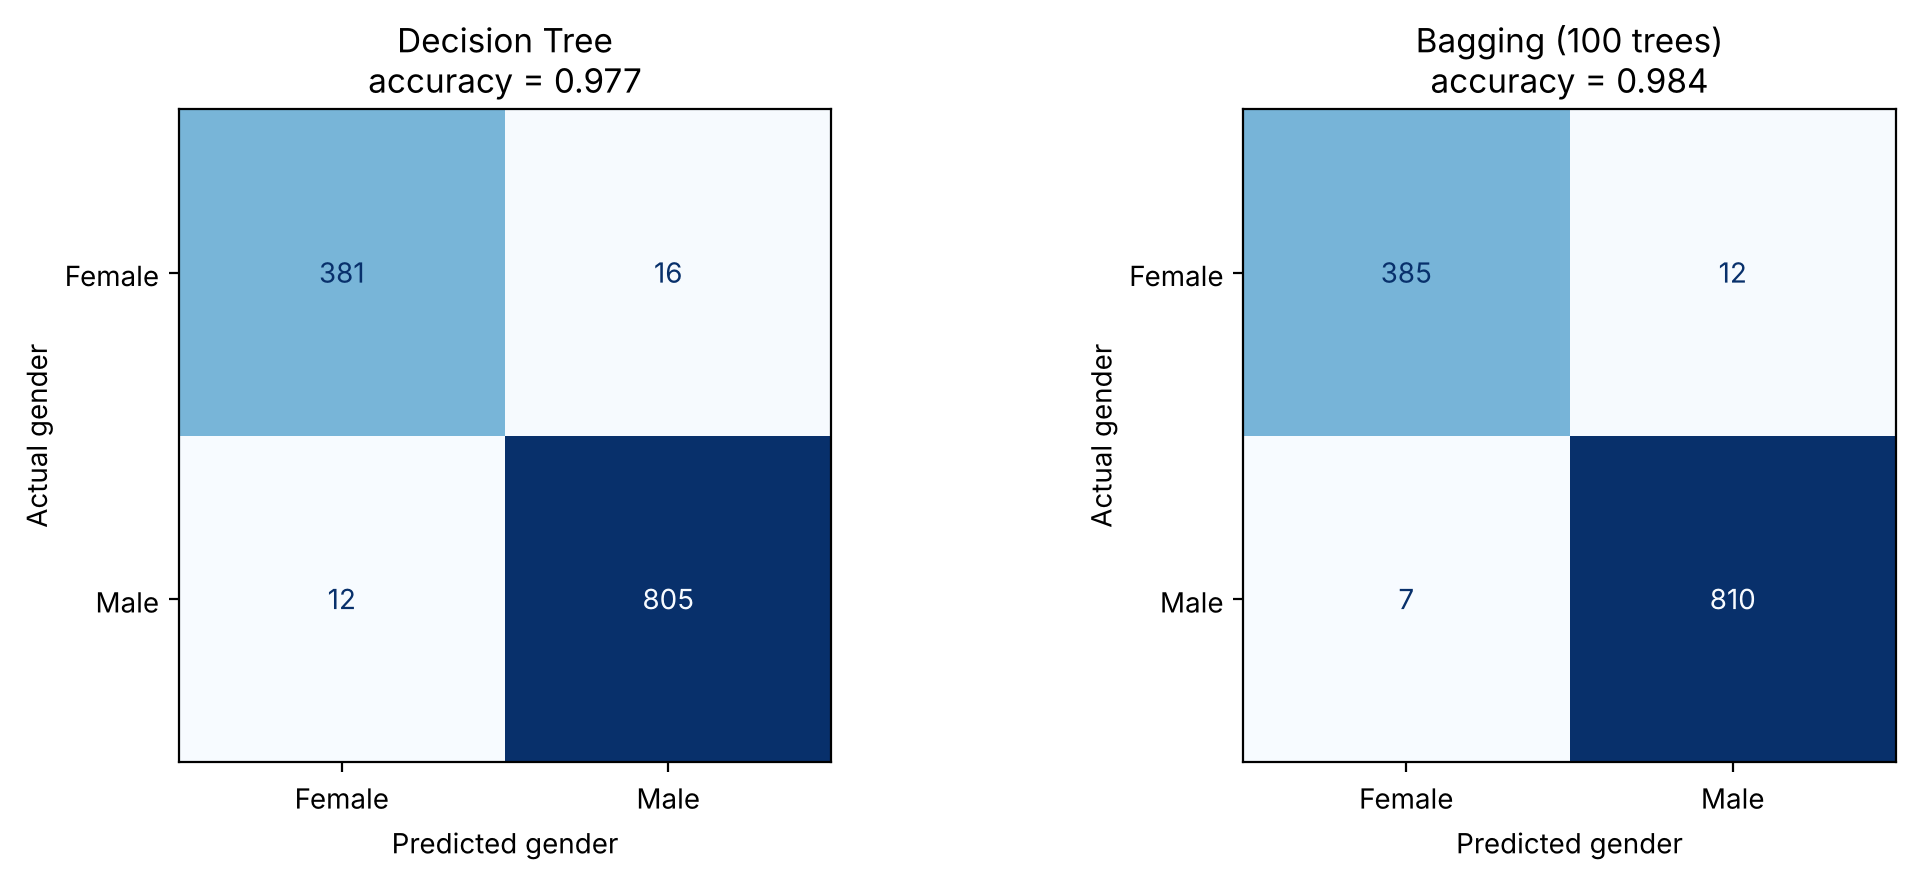

Bagging:
              precision    recall  f1-score   support

      Female       0.98      0.97      0.98       397
        Male       0.99      0.99      0.99       817

    accuracy                           0.98      1214
   macro avg       0.98      0.98      0.98      1214
weighted avg       0.98      0.98      0.98      1214



In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, {'Decision Tree': tree, 'Bagging (100 trees)': bag}.items()):
    cm = confusion_matrix(y_test, m.predict(X_test))
    ConfusionMatrixDisplay(cm, display_labels=['Female', 'Male']).plot(ax=ax, cmap='Blues', colorbar=False)
    ax.set_title(f'{name}\naccuracy = {accuracy_score(y_test, m.predict(X_test)):.3f}')
    ax.set_xlabel('Predicted gender'); ax.set_ylabel('Actual gender')
plt.tight_layout(); plt.show()
print('Bagging:'); print(classification_report(y_test, bag.predict(X_test), target_names=['Female', 'Male']))

**Results.** With the same stratified split (`random_state=42`), a single Decision Tree reaches **97.7 %** test accuracy, whereas the bagged ensemble of 100 trees reaches **98.4 %**, so bagging cuts the number of test errors from 28 to 19 (confusion matrices above: tree 16 women labelled male + 12 men labelled female; bagging 12 + 7). Both models fit the training set perfectly (train accuracy 1.0), so the gain comes from lower variance on unseen data rather than from a better fit. Most remaining errors are women predicted as men, the minority class, and the whole figure is high because many measurements (height, weight, chest and hand dimensions…) separate the sexes well.